# Univariate Volatility Modelling and Value-at-Risk: NVDA

## Overview
This notebook analyses the daily return dynamics of **NVIDIA (NVDA)** from January 2010 to December 2025 (4,024 observations) and builds a univariate market-risk model. The goal is to move from the stylised facts of equity returns to a one-day-ahead **Value-at-Risk (VaR)** estimate.

## Objectives
1. Describe the statistical properties of NVDA returns: fat tails, non-normality and volatility clustering.
2. Test for dependence in returns and squared returns (ACF, Ljung-Box).
3. Model conditional volatility with a **GJR-GARCH(1,1)** that captures the asymmetric (leverage) effect.
4. Validate the model through standardised-residual diagnostics (Ljung-Box, ARCH-LM, Q-Q plots).
5. Select the innovation distribution (Normal, Student-t, GED, Skewed Student-t) using AIC/BIC.
6. Compute one-day VaR at 95%, 99% and 99.9%, and compare how the distributional assumption changes tail risk.

## Workflow
**Data and returns** → **Distribution analysis** (kernel density, Gaussian mixtures) → **Dependence tests** → **GJR-GARCH estimation** → **Residual diagnostics** → **Distribution selection** → **VaR**

## Methodological Notes
- Returns are modelled as **log-returns** (time-additive and the standard input for GARCH likelihoods) and scaled by 100, so volatilities and VaR are in percentage points.
- Data are dividend- and split-adjusted closes downloaded from Yahoo Finance (`yfinance`), so small numerical differences may appear if the provider revises history.
- The main tools are `arch`, `statsmodels`, `scipy` and `scikit-learn`.

*This notebook is the univariate foundation for* `Modelling2_multivariate.ipynb`, *which extends the analysis to a multi-asset portfolio with dynamic correlations.*

# Libraries and Data

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

ticker = "NVDA"

data = yf.download(
    ticker,
    start="2010-01-01",
    end="2026-01-01",
    interval="1d",
    auto_adjust=True
)

# Cierre

prices = data[["Close"]].copy()

prices.columns = ["Price"]

print(data.head())
print("************************************************")
print(prices.head())


[*********************100%***********************]  1 of 1 completed

Price          Close      High       Low      Open     Volume
Ticker          NVDA      NVDA      NVDA      NVDA       NVDA
Date                                                         
2010-01-04  0.422817  0.425790  0.414128  0.423275  800204000
2010-01-05  0.428991  0.433565  0.421217  0.421217  728648000
2010-01-06  0.431736  0.432650  0.424647  0.428763  649168000
2010-01-07  0.423275  0.431278  0.420073  0.429449  547792000
2010-01-08  0.424189  0.427162  0.417329  0.419845  478168000
************************************************
               Price
Date                
2010-01-04  0.422817
2010-01-05  0.428991
2010-01-06  0.431736
2010-01-07  0.423275
2010-01-08  0.424189


In [2]:
# Returns

returns = prices.pct_change()

returns.columns = ["Return"]

# LOG-returns

log_returns = np.log(prices / prices.shift(1))
log_returns.columns = ["Log_Return"]
returns = returns.iloc[1:]
log_returns = log_returns.iloc[1:]

# Returns Df

df = pd.concat(
    [prices, returns, log_returns],
    axis=1
)

print(df.head())

               Price    Return  Log_Return
Date                                      
2010-01-04  0.422817       NaN         NaN
2010-01-05  0.428991  0.014603    0.014497
2010-01-06  0.431736  0.006397    0.006376
2010-01-07  0.423275 -0.019598   -0.019792
2010-01-08  0.424189  0.002161    0.002159


In [3]:
# NaN values
print(df.isnull().sum())
df = df.fillna(df.mean())

Price         0
Return        1
Log_Return    1
dtype: int64


In [4]:
# Info and Describe
print("\nInformación:")
print(df.info())

print("\nEstadísticos:")
print(df.describe())



Información:
<class 'pandas.DataFrame'>
DatetimeIndex: 4024 entries, 2010-01-04 to 2025-12-31
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Price       4024 non-null   float64
 1   Return      4024 non-null   float64
 2   Log_Return  4024 non-null   float64
dtypes: float64(3)
memory usage: 125.8 KB
None

Estadísticos:
             Price       Return   Log_Return
count  4024.000000  4024.000000  4024.000000
mean     22.614257     0.001925     0.001513
std      43.889842     0.028786     0.028607
min       0.203062    -0.187559    -0.207712
25%       0.428597    -0.012359    -0.012436
50%       3.969654     0.001777     0.001738
75%      17.501292     0.016324     0.016192
max     206.545166     0.298067     0.260876


# Initial Exploration

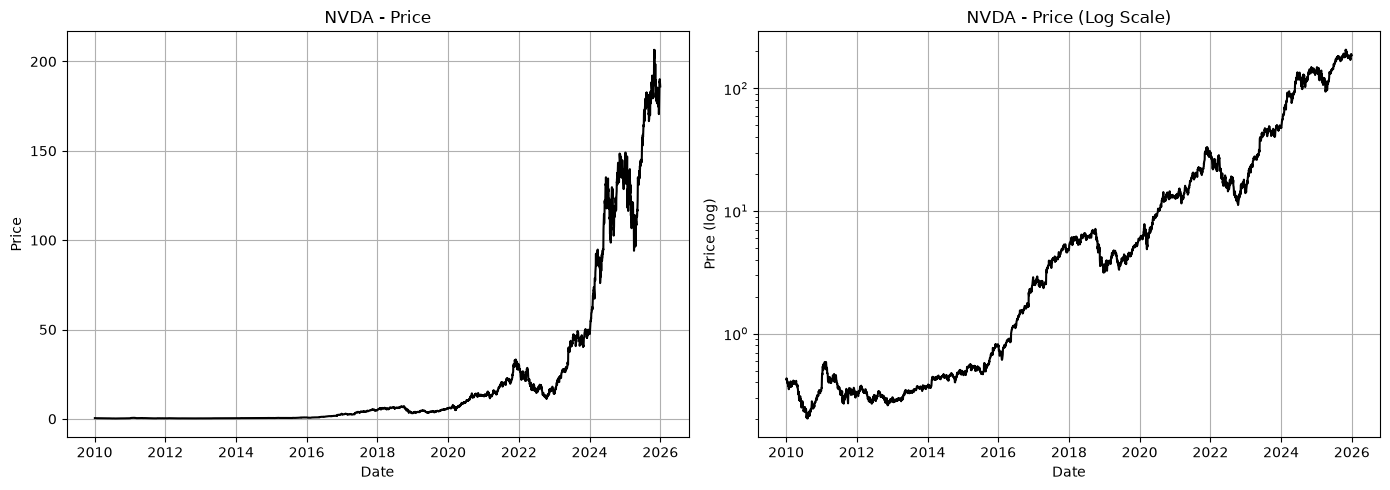

In [5]:
# Returns Graphs

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precio normal
axes[0].plot(df.index, df["Price"], color="black")
axes[0].set_title("NVDA - Price")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price")
axes[0].grid()

# Precio en escala log
axes[1].plot(df.index, df["Price"], color="black")
axes[1].set_yscale("log")
axes[1].set_title("NVDA - Price (Log Scale)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Price (log)")
axes[1].grid()

plt.tight_layout()
plt.show()

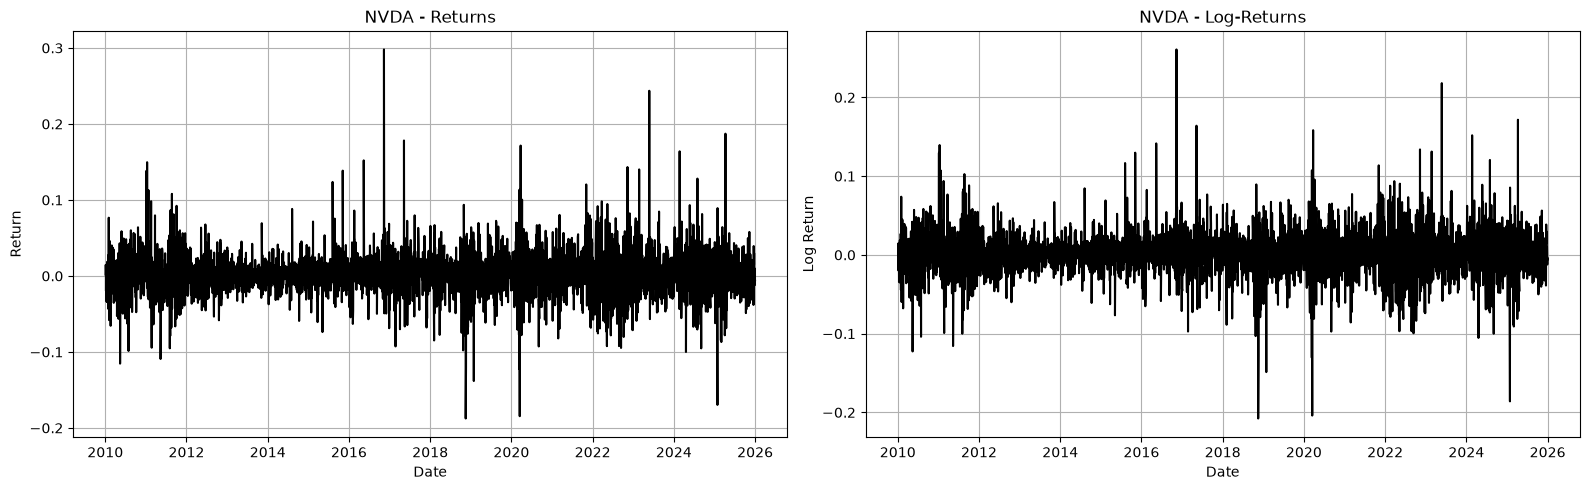

In [6]:


# Returns and Log-Returns Graphs

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Returns
sns.lineplot(
    data=df,
    x=df.index,
    y="Return",
    ax=axes[0],
    color="black",
)

axes[0].set_title("NVDA - Returns")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Return")
axes[0].grid()

# Log-Returns
sns.lineplot(
    data=df,
    x=df.index,
    y="Log_Return",
    ax=axes[1],
    color="black"
)

axes[1].set_title("NVDA - Log-Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return")
axes[1].grid()

plt.tight_layout()
plt.show()

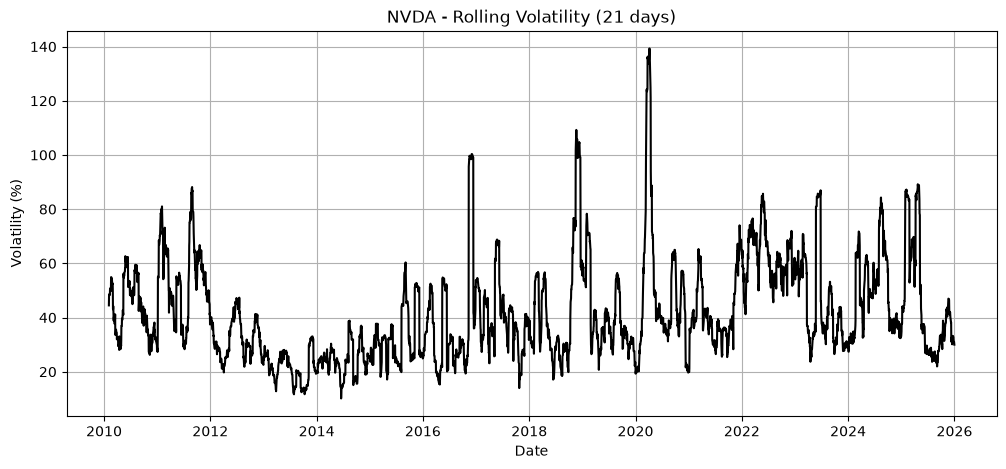

In [7]:
plt.figure(figsize=(12, 5)) 

sns.lineplot(
    data = df,
    x = "Date",
    y = 100 * np.log(df["Price"]/df["Price"].shift(1)).rolling(21).std() * np.sqrt(252),
    color = "black"
)

plt.title("NVDA - Rolling Volatility (21 days)")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")
plt.grid()

# Distribution Analysis


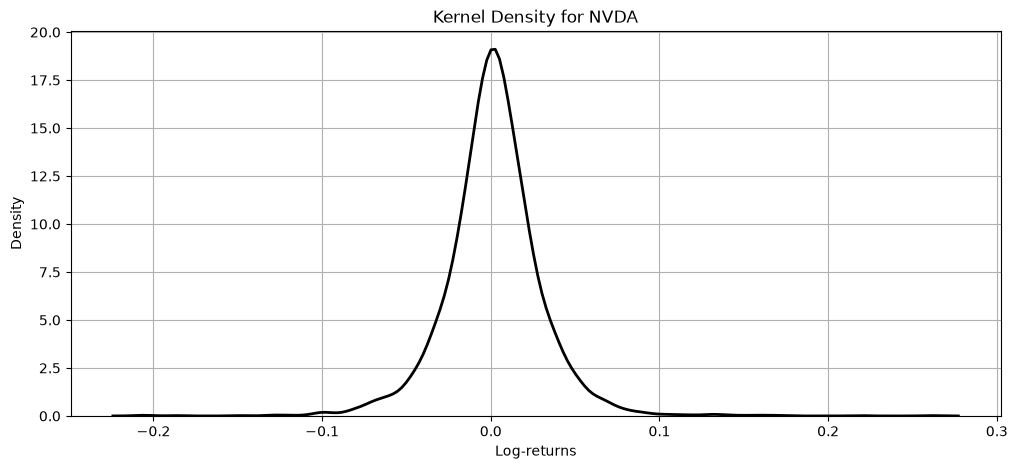

In [8]:
plt.figure(figsize=(12, 5))

sns.kdeplot(
    data=df,
    x="Log_Return",
    color="black",
    linewidth=2
)

plt.xlabel("Log-returns")
plt.ylabel("Density")
plt.title("Kernel Density for NVDA")

plt.grid()
plt.show()

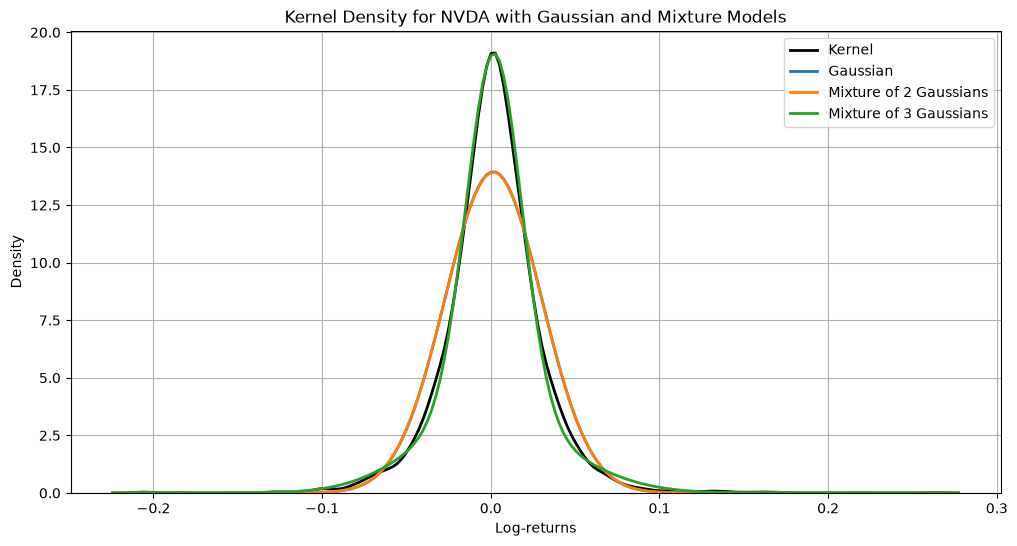

Mixture of 2 Gaussians
Weights: [0.54177626 0.45822374]
Means: [ 0.00786478 -0.00599691]
Standard deviations: [0.0277508  0.02780315]

Mixture of 3 Gaussians
Weights: [0.17718418 0.17051787 0.65229796]
Means: [ 0.01947945 -0.01895843  0.00198426]
Standard deviations: [0.04005576 0.03685832 0.01635128]


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.mixture import GaussianMixture

x = df["Log_Return"].dropna().values

plt.figure(figsize=(12, 6))

kde = sns.kdeplot(x=x, color="black", linewidth=2, label="Kernel")

kde_x = kde.get_lines()[0].get_xdata()
kde_y = kde.get_lines()[0].get_ydata()

normal = norm.pdf(kde_x, np.mean(x), np.std(x))

mixfit_2 = GaussianMixture(n_components=2, random_state=42)
mixfit_2.fit(x.reshape(-1, 1))

weights_2 = mixfit_2.weights_
means_2 = mixfit_2.means_.flatten()
stds_2 = np.sqrt(mixfit_2.covariances_.flatten())

mix_2 = sum(
    weights_2[i] * norm.pdf(kde_x, means_2[i], stds_2[i])
    for i in range(2)
)

mixfit_3 = GaussianMixture(n_components=3, random_state=42)
mixfit_3.fit(x.reshape(-1, 1))

weights_3 = mixfit_3.weights_
means_3 = mixfit_3.means_.flatten()
stds_3 = np.sqrt(mixfit_3.covariances_.flatten())

mix_3 = sum(
    weights_3[i] * norm.pdf(kde_x, means_3[i], stds_3[i])
    for i in range(3)
)

plt.plot(kde_x, normal, linewidth=2, label="Gaussian")
plt.plot(kde_x, mix_2, linewidth=2, label="Mixture of 2 Gaussians")
plt.plot(kde_x, mix_3, linewidth=2, label="Mixture of 3 Gaussians")
plt.xlabel("Log-returns")
plt.ylabel("Density")
plt.title("Kernel Density for NVDA with Gaussian and Mixture Models")
plt.legend()
plt.grid()
plt.show()

print("Mixture of 2 Gaussians")
print("Weights:", weights_2)
print("Means:", means_2)
print("Standard deviations:", stds_2)

print("\nMixture of 3 Gaussians")
print("Weights:", weights_3)
print("Means:", means_3)
print("Standard deviations:", stds_3)

The log-returns of NVDA are highly concentrated around zero and exhibit a pronounced peak with relatively heavy tails. The single Gaussian distribution does not fully capture the empirical shape of the returns. Mixture models provide a more flexible representation, with the three-Gaussian mixture appearing to fit the kernel density particularly well. This suggests that NVDA returns may exhibit non-normal and potentially heterogeneous behavior that is better captured by a mixture distribution.

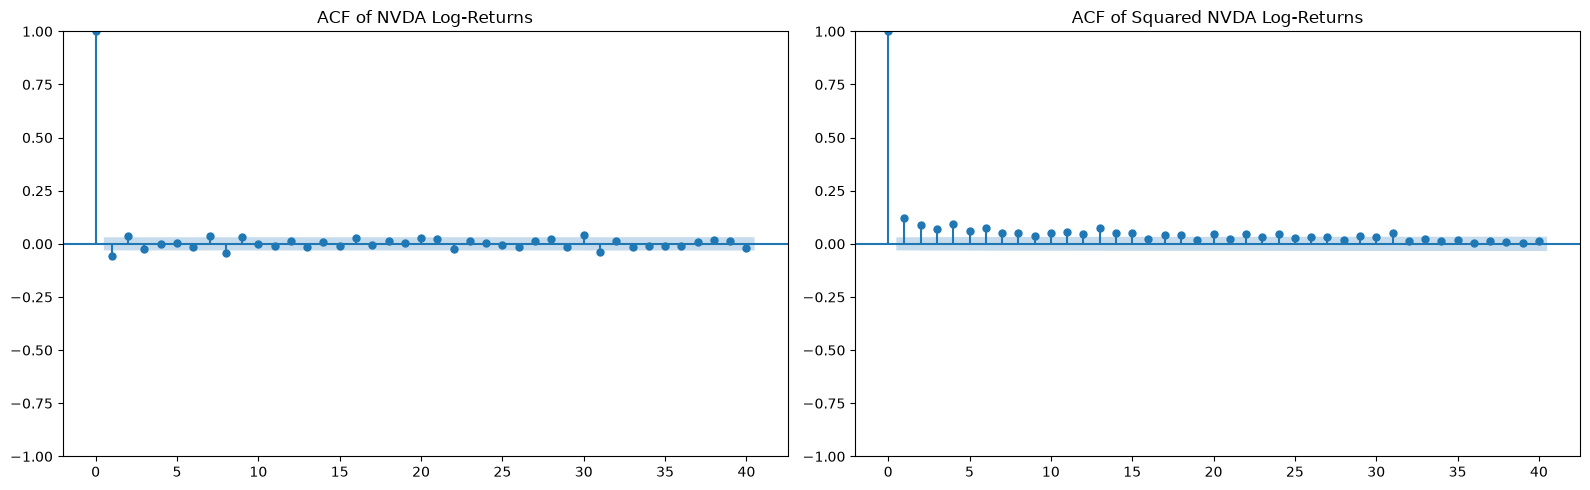

In [10]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(
    df["Log_Return"].dropna(),
    lags=40,
    alpha=0.05,
    ax=axes[0],
    title="ACF of NVDA Log-Returns"
)

plot_acf(
    df["Log_Return"].dropna() ** 2,
    lags=40,
    alpha=0.05,
    ax=axes[1],
    title="ACF of Squared NVDA Log-Returns"
)

plt.tight_layout()
plt.show()

The ACF of the log-returns shows little evidence of significant autocorrelation, suggesting that returns are approximately uncorrelated over time. In contrast, the squared log-returns exhibit significant positive autocorrelation, indicating volatility clustering: periods of high (or low) volatility tend to be followed by periods of similarly high (or low) volatility. This is a common feature of financial returns and provides motivation for using GARCH-type models.

In [11]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_lr = acorr_ljungbox(
    df["Log_Return"].dropna(),
    lags=[10, 20, 30, 40],
    return_df=True
)

lb_lr2 = acorr_ljungbox(
    df["Log_Return"].dropna() ** 2,
    lags=[10, 20, 30, 40],
    return_df=True
)

print("Ljung-Box: Log-Rendimientos")
print(lb_lr)

print("\nLjung-Box: Log-Rendimientos²")
print(lb_lr2)

Ljung-Box: Log-Rendimientos
      lb_stat  lb_pvalue
10  39.645035   0.000020
20  48.956861   0.000312
30  65.751506   0.000176
40  77.824220   0.000317

Ljung-Box: Log-Rendimientos²
       lb_stat     lb_pvalue
10  222.563045  3.106560e-42
20  312.401757  2.353986e-54
30  358.679121  5.753808e-58
40  375.945113  3.413885e-56


# GARCH-Fit

## Univariate GJR-GARCH

For the asset, returns are modeled as:

$$
r_t = \mu + \varepsilon_t,
\qquad
\varepsilon_t = \sigma_t z_t
$$

where the conditional variance follows a GJR-GARCH(1,1) specification:

$$
\sigma_t^2 =
\omega
+
\left(
\alpha +
\gamma\,\mathbb{1}_{\{\varepsilon_{t-1}<0\}}
\right)
\varepsilon_{t-1}^2
+
\beta\,\sigma_{t-1}^2
$$

The indicator function $\mathbb{1}*{{\varepsilon*{t-1}<0}}$ captures the asymmetric effect of negative shocks on volatility.



In [12]:
from arch import arch_model

Iberdrola_lr = df["Log_Return"].dropna() * 100

GARCH = arch_model(
    Iberdrola_lr,
    mean="Constant",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    o=1,
    dist="normal"
)

GARCH_fit = GARCH.fit(disp="off")

print(GARCH_fit.summary())

                   Constant Mean - GJR-GARCH Model Results                    
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                  GJR-GARCH   Log-Likelihood:               -9644.24
Distribution:                  Normal   AIC:                           19298.5
Method:            Maximum Likelihood   BIC:                           19330.0
                                        No. Observations:                 4024
Date:                Thu, Oct 29 2026   Df Residuals:                     4023
Time:                        19:19:33   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1725  4.327e-02      3.986  6.724e-05 [8.766e-0

The GJR-GARCH model indicates strong persistence in NVDA volatility, as reflected by the highly significant $\beta$ coefficient (0.8701). The positive and statistically significant $\gamma$ coefficient (0.0852, $p=0.0286$) provides evidence of an asymmetric volatility response, with negative shocks having an additional impact on conditional volatility. The $\alpha$ coefficient is marginally significant ($p=0.0607$), while the constant mean is statistically significant. Overall, the results suggest persistent and asymmetric volatility dynamics in NVDA returns.

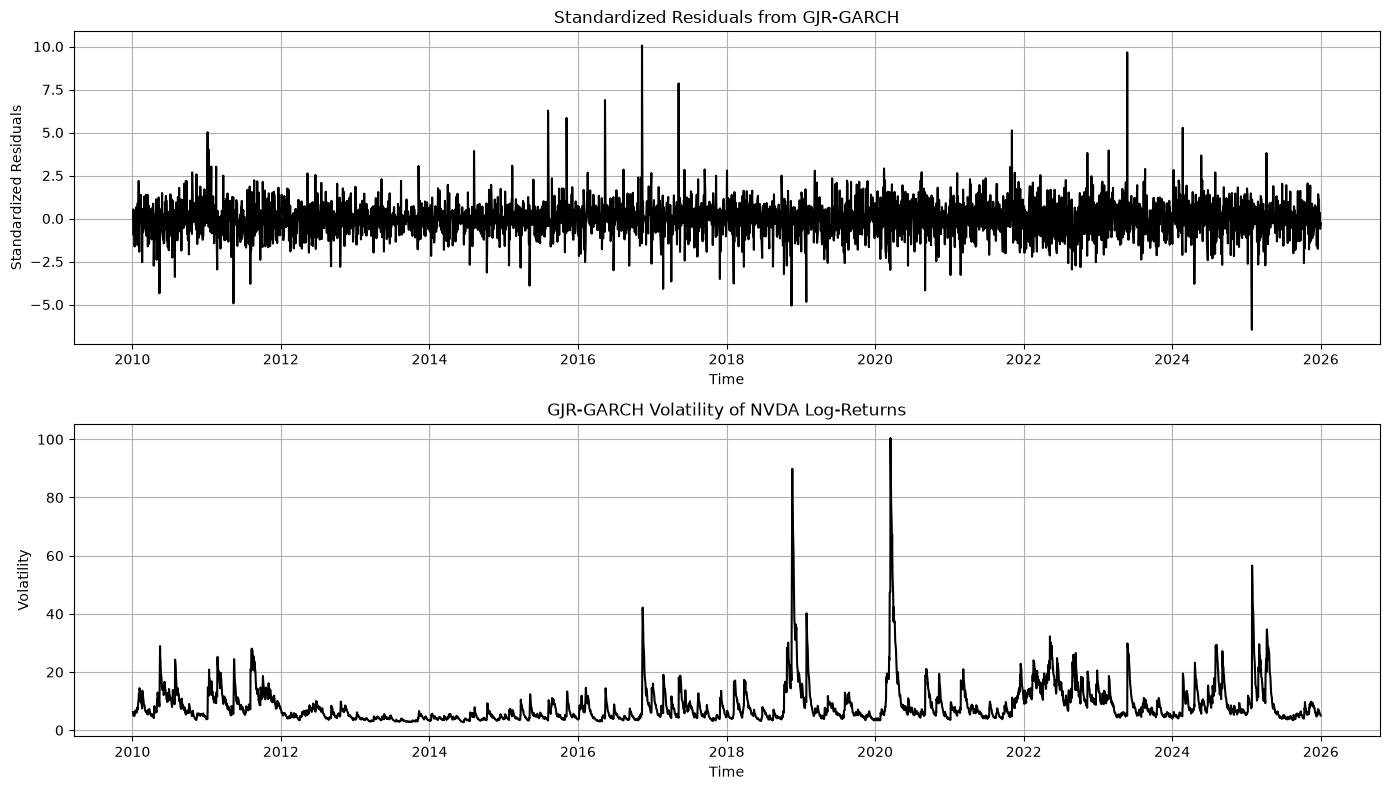

In [13]:
from arch import arch_model
import matplotlib.pyplot as plt

nvda_lr = df["Log_Return"].dropna() * 100

GARCH = arch_model(
    nvda_lr,
    mean="constant",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    o=1,
    dist="normal"
)

GARCH_fit = GARCH.fit(disp="off")

standardized_residuals = GARCH_fit.std_resid
nvda_GARCH_vol = GARCH_fit.conditional_volatility ** 2

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(standardized_residuals, color="black")
axes[0].set_title("Standardized Residuals from GJR-GARCH")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Standardized Residuals")
axes[0].grid()

axes[1].plot(nvda_GARCH_vol, color="black")
axes[1].set_title("GJR-GARCH Volatility of NVDA Log-Returns")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Volatility")
axes[1].grid()

plt.tight_layout()
plt.show()


In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
diag = pd.DataFrame({
    "Ljung-Box(10) z²": [
        acorr_ljungbox(
            standardized_residuals.dropna() ** 2,
            lags=[10]
        )["lb_pvalue"].iloc[0]
    ],
    "ARCH-LM(10)": [
        het_arch(
            standardized_residuals.dropna(),
            nlags=10
        )[1]
    ]
}, index=["p-value"]).round(4)

display(diag)

,Ljung-Box(10) z²,ARCH-LM(10)
p-value,0.9198,0.9192


For NVDA, both tests report high p-values: 0.8976 for the Ljung-Box(10) test applied to the squared standardized residuals and 0.8899 for the ARCH-LM(10) test. Therefore, the null hypotheses of no remaining autocorrelation in the squared residuals and no remaining ARCH effects cannot be rejected. This suggests that the GARCH(1,1) model adequately captures the volatility dynamics of NVDA, with no statistically significant evidence of additional conditional heteroskedasticity remaining in the standardized residuals.

# Innovations Distribution

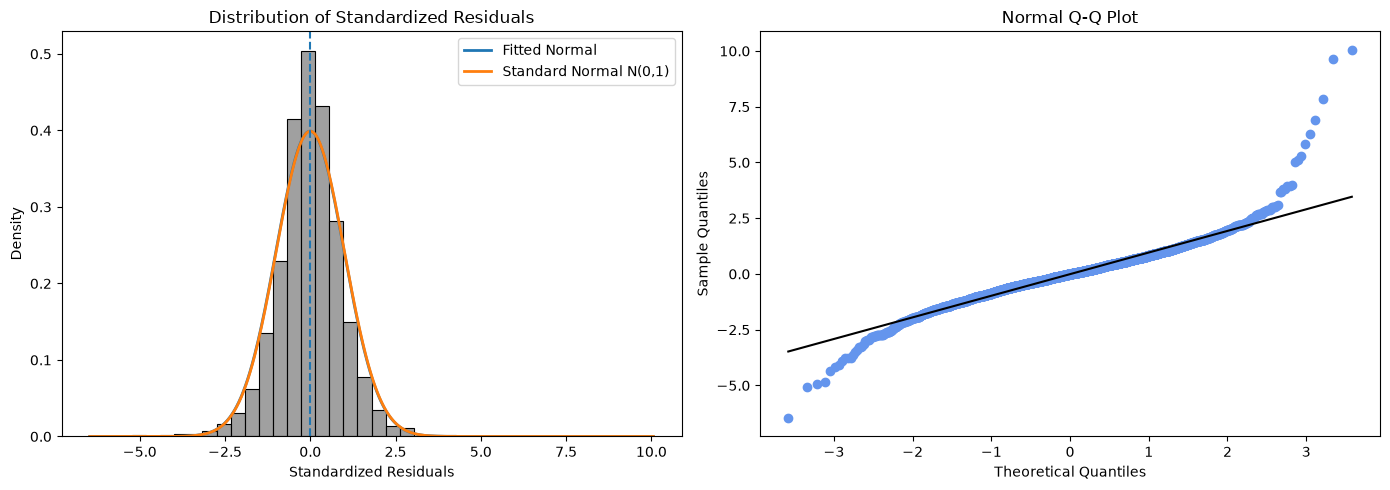

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, probplot

std_resid = GARCH_fit.std_resid.dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram + density
sns.histplot(
    std_resid,
    bins=40,
    stat="density",
    color="gray",
    ax=axes[0]
)

x = np.linspace(std_resid.min(), std_resid.max(), 500)

axes[0].plot(
    x,
    norm.pdf(
        x,
        np.mean(std_resid),
        np.std(std_resid)
    ),
    linewidth=2,
    label="Fitted Normal"
)

axes[0].plot(
    x,
    norm.pdf(x, 0, 1),
    linewidth=2,
    label="Standard Normal N(0,1)"
)

axes[0].axvline(0, linestyle="--")
axes[0].set_title("Distribution of Standardized Residuals")
axes[0].set_xlabel("Standardized Residuals")
axes[0].set_ylabel("Density")
axes[0].legend()


# Q-Q Plot
probplot(
    std_resid,
    dist="norm",
    plot=axes[1]
)

lines = axes[1].get_lines()
lines[0].set_color("cornflowerblue")
lines[1].set_color("black")

axes[1].set_title("Normal Q-Q Plot")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")

plt.tight_layout()
plt.show()

In [16]:
from arch import arch_model
import pandas as pd

returns = df["Log_Return"].dropna() * 100

model_norm = arch_model(
    returns,
    mean="constant",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

model_t = arch_model(
    returns,
    mean="constant",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

model_ged = arch_model(
    returns,
    mean="constant",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="ged"
)

model_skewt = arch_model(
    returns,
    mean="constant",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="skewt"
)

fit_norm = model_norm.fit(disp="off")
fit_t = model_t.fit(disp="off")
fit_ged = model_ged.fit(disp="off")
fit_skewt = model_skewt.fit(disp="off")

resultados = pd.DataFrame({
    "Distribución": ["Normal", "Student-t", "GED", "Skewed Student-t"],
    "Log-Likelihood": [
        fit_norm.loglikelihood,
        fit_t.loglikelihood,
        fit_ged.loglikelihood,
        fit_skewt.loglikelihood
    ],
    "AIC": [
        fit_norm.aic,
        fit_t.aic,
        fit_ged.aic,
        fit_skewt.aic
    ],
    "BIC": [
        fit_norm.bic,
        fit_t.bic,
        fit_ged.bic,
        fit_skewt.bic
    ]
})

print(resultados.sort_values("AIC"))

       Distribución  Log-Likelihood           AIC           BIC
1         Student-t    -9354.304642  18718.609285  18750.109443
3  Skewed Student-t    -9353.983897  18719.967794  18757.767984
2               GED    -9399.778533  18809.557067  18841.057225
0            Normal    -9659.298494  19326.596987  19351.797114


The Student-t distribution provides the most favorable balance between goodness of fit and model complexity, achieving the lowest AIC and BIC. Although the Skewed Student-t distribution achieves the highest log-likelihood, its improvement in fit is marginal and does not compensate for the additional model complexity according to AIC and BIC. Both Student-t specifications substantially outperform the Normal and GED distributions.

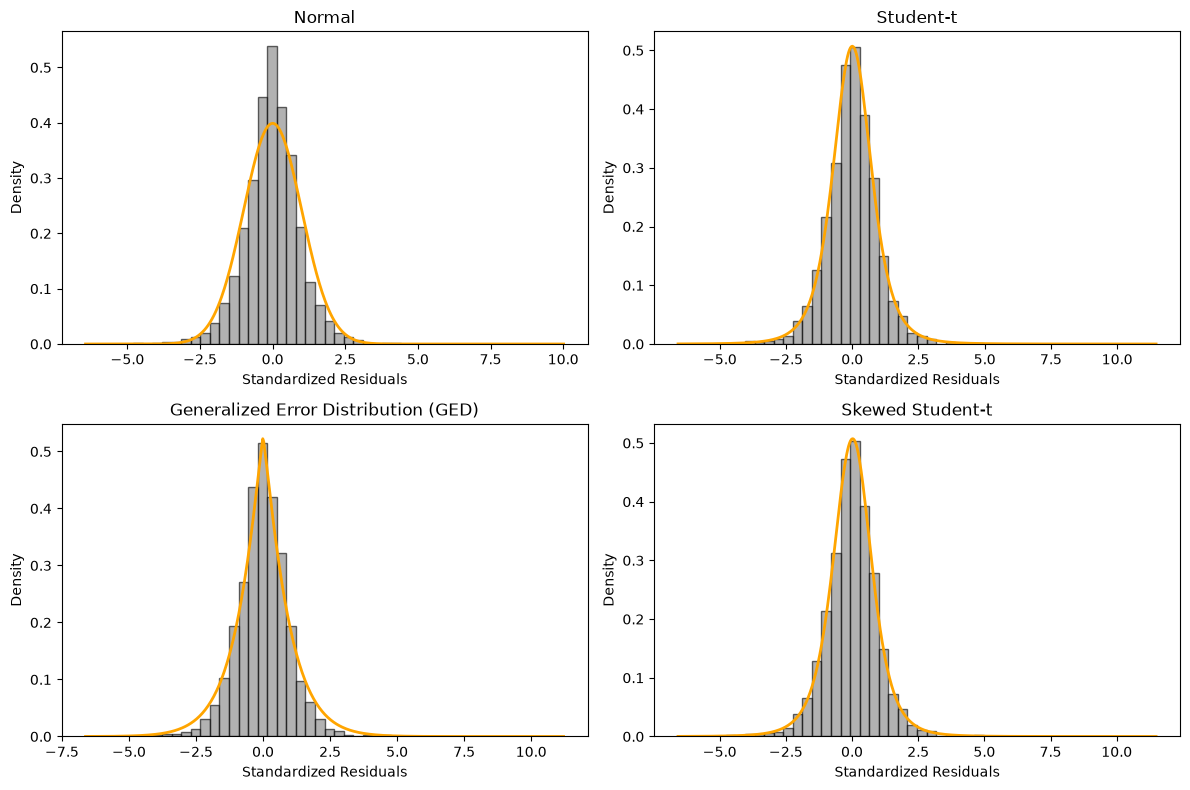

In [17]:
import matplotlib.pyplot as plt
import numpy as np

from scipy.stats import norm, t, gennorm
from scipy.special import gammaln


fig, axes = plt.subplots(2, 2, figsize=(12, 8))


# -------------------------
# Normal
# -------------------------

z = fit_norm.std_resid.dropna()

axes[0, 0].hist(
    z,
    bins=50,
    density=True,
    alpha=0.6,
    color="gray",
    edgecolor="black"
)

x = np.linspace(z.min(), z.max(), 500)

axes[0, 0].plot(
    x,
    norm.pdf(x),
    color="orange",
    linewidth=2
)

axes[0, 0].set_title("Normal")
axes[0, 0].set_xlabel("Standardized Residuals")
axes[0, 0].set_ylabel("Density")


# -------------------------
# Student-t
# -------------------------

z = fit_t.std_resid.dropna()

axes[0, 1].hist(
    z,
    bins=50,
    density=True,
    alpha=0.6,
    color="gray",
    edgecolor="black"
)

x = np.linspace(z.min(), z.max(), 500)

nu = fit_t.params["nu"]
scale = np.sqrt(nu / (nu - 2))

y = t.pdf(x * scale, df=nu) * scale

axes[0, 1].plot(
    x,
    y,
    color="orange",
    linewidth=2
)

axes[0, 1].set_title("Student-t")
axes[0, 1].set_xlabel("Standardized Residuals")
axes[0, 1].set_ylabel("Density")


# -------------------------
# GED
# -------------------------

z = fit_ged.std_resid.dropna()

axes[1, 0].hist(
    z,
    bins=50,
    density=True,
    alpha=0.6,
    color="gray",
    edgecolor="black"
)

x = np.linspace(z.min(), z.max(), 500)

nu = fit_ged.params["nu"]

y = gennorm.pdf(
    x,
    beta=nu
)

y = y / np.trapezoid(y, x)

axes[1, 0].plot(
    x,
    y,
    color="orange",
    linewidth=2
)

axes[1, 0].set_title("Generalized Error Distribution (GED)")
axes[1, 0].set_xlabel("Standardized Residuals")
axes[1, 0].set_ylabel("Density")


# -------------------------
# Skewed Student-t
# -------------------------

z = fit_skewt.std_resid.dropna()

axes[1, 1].hist(
    z,
    bins=50,
    density=True,
    alpha=0.6,
    color="gray",
    edgecolor="black"
)

x = np.linspace(z.min(), z.max(), 500)

eta = fit_skewt.params["eta"]
lam = fit_skewt.params["lambda"]

# Constants of Hansen's standardized skewed Student-t
c = np.exp(
    gammaln((eta + 1) / 2)
    - gammaln(eta / 2)
) / np.sqrt(np.pi * (eta - 2))

a = 4 * lam * c * ((eta - 2) / (eta - 1))

b = np.sqrt(1 + 3 * lam**2 - a**2)

y = np.zeros_like(x)

threshold = -a / b

left = x < threshold
right = x >= threshold

y[left] = (
    b * c
    * (
        1
        + (
            (b * x[left] + a)
            / (1 - lam)
        )**2
        / (eta - 2)
    ) ** (-(eta + 1) / 2)
)

y[right] = (
    b * c
    * (
        1
        + (
            (b * x[right] + a)
            / (1 + lam)
        )**2
        / (eta - 2)
    ) ** (-(eta + 1) / 2)
)

axes[1, 1].plot(
    x,
    y,
    color="orange",
    linewidth=2
)

axes[1, 1].set_title("Skewed Student-t")
axes[1, 1].set_xlabel("Standardized Residuals")
axes[1, 1].set_ylabel("Density")


plt.tight_layout()
plt.show()

The standardized residuals suggest that the Normal distribution may not adequately capture the heavy tails present in the data. The Student-t and Skewed Student-t distributions provide a better fit, as they account for extreme observations more effectively. Overall, the residuals appear to be better characterized by a heavy-tailed distribution, with the Student-t specification being a suitable choice for the GARCH model.

# VAR

In [18]:
from scipy.stats import norm, t, gennorm
import numpy as np
import pandas as pd

# -------------------------
# GARCH Forecasts
# -------------------------

forecasts = {
    "Normal": fit_norm.forecast(horizon=1),
    "Student-t": fit_t.forecast(horizon=1),
    "GED": fit_ged.forecast(horizon=1),
    "Skewed Student-t": fit_skewt.forecast(horizon=1)
}

fits = {
    "Normal": fit_norm,
    "Student-t": fit_t,
    "GED": fit_ged,
    "Skewed Student-t": fit_skewt
}

probabilities = np.array([0.05, 0.01, 0.001])

var_results = []


# -------------------------
# Normal, Student-t, GED
# and Skewed Student-t
# -------------------------

for name, fit in fits.items():

    forecast = forecasts[name]

    mu = forecast.mean.iloc[-1, 0]

    sigma = np.sqrt(
        forecast.variance.iloc[-1, 0]
    )

    dist = fit.model.distribution

    param_names = dist.parameter_names()

    dist_params = [
        fit.params[param]
        for param in param_names
    ]

    quantiles = dist.ppf(
        probabilities,
        parameters=dist_params
    )

    for level, q in zip(probabilities, quantiles):

        var = mu + sigma * q

        var_results.append({
            "Distribution": name,
            "Confidence Level": f"{level * 100:.1f}%",
            "Expected Return": mu,
            "Volatility": sigma,
            "VaR": var,
            "VaR Loss (%)": -var
        })


# -------------------------
# Final DataFrame
# -------------------------

var_results = pd.DataFrame(var_results)

var_results

,Distribution,Confidence Level,Expected Return,Volatility,VaR,VaR Loss (%)
0,Normal,5.0%,0.198117,2.185529,-3.396758,3.396758
1,Normal,1.0%,0.198117,2.185529,-4.886184,4.886184
2,Normal,0.1%,0.198117,2.185529,-6.555675,6.555675
3,Student-t,5.0%,0.153313,2.176903,-3.196693,3.196693
4,Student-t,1.0%,0.153313,2.176903,-5.570888,5.570888
5,Student-t,0.1%,0.153313,2.176903,-10.280461,10.280461
6,GED,5.0%,0.165735,2.158937,-3.381645,3.381645
7,GED,1.0%,0.165735,2.158937,-5.606263,5.606263
8,GED,0.1%,0.165735,2.158937,-8.621500,8.621500
9,Skewed Student-t,5.0%,0.140599,2.177138,-3.235534,3.235534


The VaR estimates increase substantially as the confidence level moves from 5% to 0.1%, reflecting greater potential losses in the tail of the return distribution. The Student-t and Skewed Student-t specifications produce the most conservative estimates at the 0.1% level, with potential losses of 10.26% and 10.49%, respectively. In contrast, the Normal distribution gives a considerably lower estimate of 6.54%, highlighting the importance of accounting for the heavy tails observed in financial returns.